# 02 – EDA và chọn zone đại diện (Giai đoạn 2)

**Checklist:** 2.14, 2.15

**Vì sao cần.** Thầy nhận xét: kết quả chỉ trên chuỗi tổng chưa đủ để kết luận. Phải chạy thêm trên vài zone **đại diện cho các kiểu hành vi khác nhau**:
1. zone có mùa vụ ổn định,
2. zone biến động mạnh,
3. zone có dấu hiệu đổi chế độ.

Zone phải được chọn **bằng số liệu**, không chọn theo cảm tính.

**Các đặc trưng dùng để mô tả một zone** (code ở `src/eda.py`):

| Đặc trưng | Ý nghĩa | Dùng cho tiêu chí |
|---|---|---|
| `prof_stab` | tương quan trung bình giữa hình dạng 24 giờ của từng ngày với hình dạng trung bình | ổn định |
| `acf24`, `acf168` | tự tương quan ở chu kỳ ngày và tuần | ổn định |
| `vol` | thay đổi tương đối trung bình của phụ tải TB ngày giữa 2 ngày liên tiếp | biến động |
| `max_yoy` | \|log(tháng này / cùng tháng năm trước)\| lớn nhất | đổi chế độ |
| `cv` | hệ số biến thiên | tham khảo |

In [1]:
import sys
sys.path.append("..")          # để import được thư mục src/ khi notebook nằm trong notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (11, 3.5)

import json
from src.data import PROCESSED, SELECTION_END
from src.eda import zone_matrix, zone_features, find_duplicates, choose_representative

In [2]:
W = zone_matrix()
dups = find_duplicates(W)
print("Các cặp zone trùng nhau hoàn toàn:", dups)

Các cặp zone trùng nhau hoàn toàn: [(3, 7)]


Zone 3 và zone 7 giống hệt nhau ở mọi giờ, nên khi chọn zone đại diện chỉ giữ zone 3.

In [3]:
feat = zone_features(W)
feat.to_csv("../results/tables/2_14_dac_trung_zone.csv")
feat.drop(columns="month_max_yoy").astype(float).round(3)

,mean_kW,cv,acf24,acf168,prof_stab,vol,max_yoy
zone,,,,,,,
1,17983.669,0.301,0.849,0.664,0.640,0.078,0.218
2,170173.718,0.197,0.858,0.731,0.815,0.067,0.146
3,183617.798,0.197,0.858,0.731,0.815,0.067,0.146
4,492.801,0.245,0.855,0.770,0.843,0.055,0.172
5,7775.107,0.330,0.873,0.707,0.743,0.080,0.211
6,177948.111,0.201,0.863,0.729,0.810,0.066,0.146
7,183617.798,0.197,0.858,0.731,0.815,0.067,0.146
8,3630.353,0.257,0.891,0.758,0.773,0.059,0.239
9,67796.001,0.242,0.191,0.104,0.277,0.153,0.341


**Về dữ liệu dùng để chọn:**
- `prof_stab`, `acf`, `vol`, `cv` chỉ tính trên dữ liệu đến `SELECTION_END` (30/06/2006).
- Riêng `max_yoy` phải nhìn cả giai đoạn thì mới thấy được bước nhảy.

Việc chọn zone là **thiết kế thí nghiệm** (chọn chuỗi nào để kiểm tra phương pháp khi chuỗi đổi chế độ), không phải đầu vào của mô hình: các mô hình vẫn chỉ được thấy dữ liệu trước origin. Em sẽ ghi rõ điểm này trong báo cáo.

In [4]:
chosen = choose_representative(feat, dups)
chosen

{'on_dinh': 4, 'bien_dong': 9, 'doi_che_do': 10}

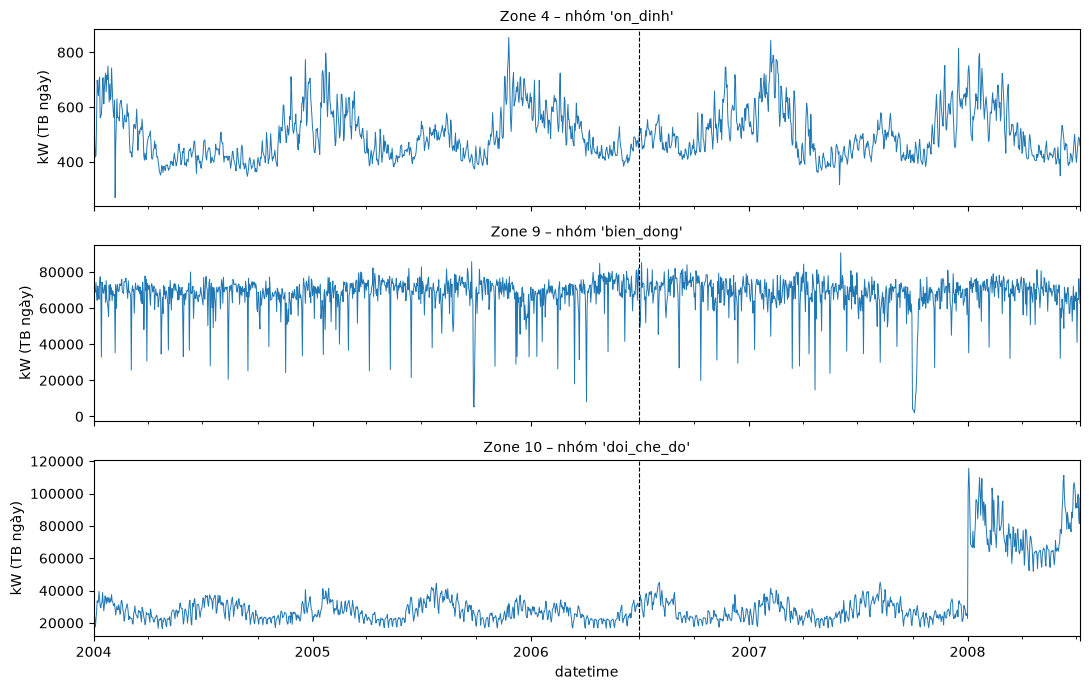

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, (nhom, z) in zip(axes, chosen.items()):
    W[z].resample("D").mean().plot(ax=ax, lw=0.7)
    ax.axvline(SELECTION_END, color="k", ls="--", lw=0.8)
    ax.set_title(f"Zone {z} – nhóm '{nhom}'", fontsize=10)
    ax.set_ylabel("kW (TB ngày)")
plt.tight_layout()
plt.savefig("../results/figures/2_14_zone_dai_dien.png", dpi=120)
plt.show()

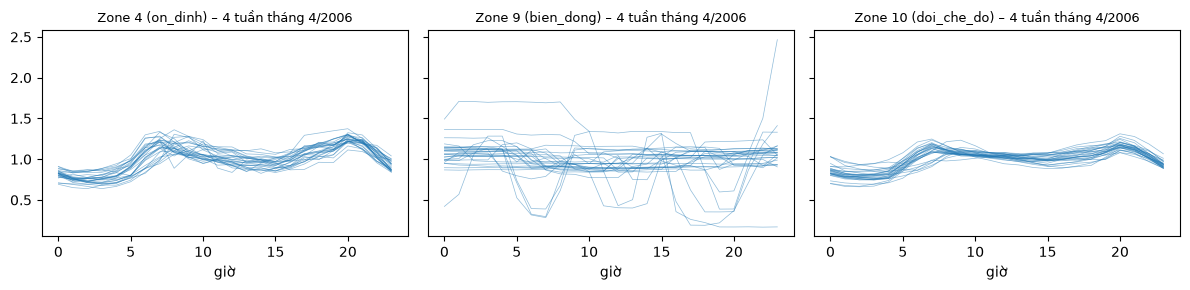

In [6]:
# So sánh hình dạng ngày (chuẩn hóa) của 3 zone: zone ổn định có các ngày gần như trùng nhau
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (nhom, z) in zip(axes, chosen.items()):
    s = W.loc["2006-04-03":"2006-04-30", z]
    prof = s.values.reshape(-1, 24)
    ax.plot((prof / prof.mean(axis=1, keepdims=True)).T, lw=0.5, color="tab:blue", alpha=0.5)
    ax.set_title(f"Zone {z} ({nhom}) – 4 tuần tháng 4/2006", fontsize=9)
    ax.set_xlabel("giờ")
plt.tight_layout(); plt.show()

## 2.15 Nhiệt độ cho từng zone đại diện

Cùng tiêu chí như chuỗi tổng: chọn trạm (hoặc `T_mean`) có R² cao nhất của hồi quy `load ~ T + T² + T³` trên dữ liệu đến `SELECTION_END`.

In [7]:
with open(PROCESSED / "zone_station.json") as f:
    mapping = json.load(f)
pd.DataFrame({"zone": list(chosen.values()), "nhom": list(chosen.keys()),
              "nhiet_do_dung": [mapping[str(z)] for z in chosen.values()]})

,zone,nhom,nhiet_do_dung
0,4,on_dinh,T_s2
1,9,bien_dong,T_s10
2,10,doi_che_do,T_s3


In [8]:
with open("../results/tables/2_14_zone_dai_dien.json", "w") as f:
    json.dump(chosen, f, indent=2)
print("đã lưu", chosen)

đã lưu {'on_dinh': 4, 'bien_dong': 9, 'doi_che_do': 10}


## Kết luận

| Nhóm | Zone | Đặc điểm nhìn thấy trên số liệu | Nhiệt độ dùng |
|---|---|---|---|
| Mùa vụ ổn định | **4** | hình dạng ngày ổn định nhất (prof_stab ≈ 0,84), ACF tuần cao, ít dao động giữa các ngày | T_s2 |
| Biến động mạnh | **9** | dao động ngày lớn nhất (vol ≈ 0,15), ACF ngày/tuần rất thấp (≈ 0,19/0,10), nhiều ngày tụt sâu → dáng tải công nghiệp | T_s10 |
| Đổi chế độ | **10** | mức tải nhảy lên khoảng 3 lần từ tháng 01/2008, rơi đúng vào **giai đoạn test** | T_s3 |

Ba zone này cùng chuỗi tổng là các chuỗi chạy thí nghiệm chính. Zone 10 là phép thử quan trọng nhất cho evaluator dựa trên "giai đoạn lịch sử tương tự": khi chế độ vừa đổi thì quá khứ không còn giống hiện tại nữa.